# Notebook 4: New Datasets and the Planned Label-Noise Test

This notebook extends the previous one. **What is new:**

1. **27 new datasets** from the same benchmark (OpenML-CC18). Together with the first 21 this gives 48 datasets.
2. **A planned test on the new datasets.** The meta-model is trained **only on the original 21 datasets** and then tested on the new datasets, which it has never seen. This checks whether the label-noise result from the first round is real.
3. Everything else (3 seeds, five methods, breakdown by problem type) is unchanged.
4. **Four figures for the paper** are made at the end and saved to the folder `figures` in your Drive (PNG at 300 dpi, and PDF). Figure 1 of the paper (the method diagram) is a separate file I made for you.

**How the new datasets were chosen (rule fixed before any results on them were seen):** all remaining OpenML-CC18 datasets with at most 10,000 rows, at most 100 columns (including the target) and at most 15 classes. 27 datasets pass this rule. None was picked or dropped by hand.

**How to run:** upload to Colab, click **Runtime → Run all**, and allow Google Drive access. Do **not** delete anything in your `data_quality_paper` folder, because your finished results are reused. Only the 27 new datasets need to run, with 3 seeds each. This will probably take about 1.5 to 2.5 hours, so keep the tab open. If Colab disconnects, run it again and it continues where it stopped. If a dataset fails, the notebook prints `FAILED` and moves on to the next one.

To test quickly first, set `FAST_TEST = True` in the third code cell (4 small datasets), and change it back afterwards. The results of a quick test are not meaningful.

In [1]:
!pip install -q openml

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 39.2 MB/s eta 0:00:00


## Setup: where results are saved

This is the same Drive folder as before, so your earlier results are found automatically.

In [2]:
import os

# Results are saved here. In Colab this is a folder in your Google Drive.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = '/content/drive/MyDrive/data_quality_paper'
except ImportError:
    OUTPUT_DIR = 'results'

os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Saving results to:', OUTPUT_DIR)

Mounted at /content/drive
Saving results to: /content/drive/MyDrive/data_quality_paper


In [3]:
import time
import glob
import warnings
import numpy as np
import pandas as pd
import openml

warnings.filterwarnings('ignore')

FAST_TEST = False       # True = only 3 small datasets, to test that everything works
SEEDS = [0, 1, 2]       # 3 repeats with different random splits
MODELS = ['logreg', 'rf', 'xgb']

# The 21 datasets from the first round (already finished)
ORIGINAL_IDS = [3, 15, 29, 31, 37, 38, 44, 50, 1049, 1067, 1480,
                11, 23, 46, 54, 307, 12, 14, 16, 22, 28]

# New datasets for the planned test. Selection rule, fixed BEFORE any results on them were seen:
# all remaining OpenML-CC18 datasets with at most 10,000 rows, at most 100 columns
# (including the target) and at most 15 classes. Exactly 27 datasets pass this rule.
NEW_IDS = [18, 182, 188, 458, 469, 1050, 1063, 1068, 1462, 1475, 1487, 1489, 1494, 1497,
           1510, 1464, 4538, 6332, 23381, 40499, 40701, 40966, 40975, 40982, 40983, 40984, 40994]

DATASET_IDS = ORIGINAL_IDS + NEW_IDS
if FAST_TEST:
    DATASET_IDS = ORIGINAL_IDS[:2] + [1063, 1464]   # two old datasets and two small new ones


def load_dataset(did):
    ds = openml.datasets.get_dataset(did)
    X, y, _, _ = ds.get_data(target=ds.default_target_attribute)
    # turn text columns into numbers, keep missing values as NaN
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            codes = X[col].astype('category').cat.codes.astype(float)
            X[col] = codes.where(codes >= 0, np.nan)
    X = X.astype(float).reset_index(drop=True)
    y = pd.factorize(y)[0]
    return X, y, ds.name

## Part A: data problems and models

Unchanged from the previous notebook. The problems are always applied in this order: wrong labels, imbalance, duplicates, missing values.

In [4]:
def inject_missing(X, level, seed=0):
    rng = np.random.default_rng(seed)
    mask = rng.random(X.shape) < level
    return X.mask(mask)


def inject_label_noise(y, level, seed=0):
    rng = np.random.default_rng(seed)
    y = y.copy()
    classes = np.unique(y)
    idx = rng.choice(len(y), int(level * len(y)), replace=False)
    for i in idx:
        y[i] = rng.choice(classes[classes != y[i]])
    return y


def inject_duplicates(X, y, level, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), int(level * len(X)), replace=True)
    X2 = pd.concat([X, X.iloc[idx]], ignore_index=True)
    y2 = np.concatenate([y, y[idx]])
    return X2, y2


def inject_imbalance(X, y, level, seed=0):
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(y, return_counts=True)
    biggest = classes[np.argmax(counts)]
    keep = []
    for c in classes:
        idx = np.where(y == c)[0]
        if c != biggest:
            n_keep = max(2, int(round(len(idx) * (1 - level))))
            idx = rng.choice(idx, n_keep, replace=False)
        keep.extend(idx)
    keep = np.sort(np.array(keep))
    return X.iloc[keep].reset_index(drop=True), y[keep]


def apply_defect(X_tr, y_tr, defect, level, seed=0):
    if defect == 'missing':
        return inject_missing(X_tr, level, seed), y_tr
    if defect == 'label_noise':
        return X_tr, inject_label_noise(y_tr, level, seed)
    if defect == 'duplicates':
        return inject_duplicates(X_tr, y_tr, level, seed)
    if defect == 'imbalance':
        return inject_imbalance(X_tr, y_tr, level, seed)
    raise ValueError('unknown defect: ' + defect)


DEFECTS = ['missing', 'label_noise', 'duplicates', 'imbalance']
DEFECT_ORDER = ['label_noise', 'imbalance', 'duplicates', 'missing']


def apply_defects(X, y, setting, seed=0):
    # setting is a dict such as {'missing': 0.2, 'label_noise': 0.1}
    for d in DEFECT_ORDER:
        if d in setting:
            X, y = apply_defect(X, y, d, setting[d], seed)
    return X, y


LEVELS = [0.05, 0.1, 0.2, 0.4]
COMBO_LEVELS = [0.1, 0.2]


def build_settings():
    settings = [{}]                       # the clean data (no problems)
    for d in DEFECTS:                     # one problem at a time
        for lv in LEVELS:
            settings.append({d: lv})
    for lv in COMBO_LEVELS:               # all four problems together
        settings.append({d: lv for d in DEFECTS})
    return settings


SETTINGS = build_settings()
print('Number of settings per dataset:', len(SETTINGS))

Number of settings per dataset: 19


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


def make_model(name):
    imputer = SimpleImputer(strategy='median')
    if name == 'logreg':
        return make_pipeline(imputer, StandardScaler(), LogisticRegression(max_iter=1000))
    if name == 'rf':
        return make_pipeline(imputer, RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0))
    if name == 'xgb':
        return make_pipeline(imputer, XGBClassifier(n_estimators=100, n_jobs=-1, random_state=0, verbosity=0))
    raise ValueError('unknown model: ' + name)

## Part B: meta-features

Unchanged. They are measured on the damaged training data, before any model is trained.

In [6]:
from scipy.stats import entropy
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

META_COLS = ['n_rows', 'n_features', 'n_classes', 'rows_per_feature',
             'missing_rate', 'duplicate_rate', 'imbalance_ratio', 'outlier_rate',
             'mean_skew', 'mean_kurtosis', 'mean_abs_corr',
             'class_entropy', 'mean_mutual_info',
             'lm_stump', 'lm_tree3', 'lm_nb']


def compute_meta_features(X, y, seed=0):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    classes, counts = np.unique(y, return_counts=True)
    prop = counts / counts.sum()

    mf = {
        'n_rows': n,
        'n_features': p,
        'n_classes': len(classes),
        'rows_per_feature': n / p,
        'missing_rate': float(X.isna().to_numpy().mean()),
        'duplicate_rate': float(X.assign(_y=y).duplicated().mean()),
        'imbalance_ratio': float(counts.min() / counts.max()),
        'class_entropy': float(entropy(prop) / np.log(len(classes))) if len(classes) > 1 else 0.0,
    }

    # outliers: share of cells more than 3 standard deviations from the column mean
    A = X.to_numpy(dtype=float)
    mu = np.nanmean(A, axis=0)
    sd = np.nanstd(A, axis=0)
    sd[sd == 0] = np.nan
    z = np.abs((A - mu) / sd)
    valid = ~np.isnan(z)
    mf['outlier_rate'] = float((z[valid] > 3).mean()) if valid.any() else 0.0

    mf['mean_skew'] = float(X.skew().mean())
    mf['mean_kurtosis'] = float(X.kurt().mean())

    if p > 1:
        C = X.corr().abs().to_numpy()
        mf['mean_abs_corr'] = float(np.nanmean(C[np.triu_indices(p, k=1)]))
    else:
        mf['mean_abs_corr'] = 0.0

    # small sample for the model-based features
    m = min(n, 1000)
    idx = rng.choice(n, m, replace=False)
    Xs = X.iloc[idx]
    ys = y[idx]
    Xi = Xs.fillna(Xs.median()).fillna(0.0).to_numpy()
    cols = rng.choice(p, min(p, 20), replace=False)

    try:
        mf['mean_mutual_info'] = float(mutual_info_classif(Xi[:, cols], ys, random_state=seed).mean())
    except Exception:
        mf['mean_mutual_info'] = np.nan

    def landmark(model):
        try:
            return float(cross_val_score(model, Xi, ys, cv=3).mean())
        except Exception:
            return np.nan

    mf['lm_stump'] = landmark(DecisionTreeClassifier(max_depth=1, random_state=0))
    mf['lm_tree3'] = landmark(DecisionTreeClassifier(max_depth=3, random_state=0))
    mf['lm_nb'] = landmark(GaussianNB())
    return mf

## Part A (continued): run the experiments

One file is saved per dataset and seed. Results from your earlier runs are reused. A dataset that fails is skipped and listed at the end.

In [7]:
def run_dataset(did, settings, seeds=(0,), models=MODELS):
    X, y, name = load_dataset(did)
    rows = []
    for seed in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.3, stratify=y, random_state=seed)
        X_tr = X_tr.reset_index(drop=True)

        clean_acc = {}
        for m in models:
            clean_acc[m] = accuracy_score(y_te, make_model(m).fit(X_tr, y_tr).predict(X_te))

        for sid, setting in enumerate(settings):
            Xd, yd = apply_defects(X_tr, y_tr, setting, seed)
            mf = compute_meta_features(Xd, yd, seed)
            for m in models:
                if setting:
                    acc = accuracy_score(y_te, make_model(m).fit(Xd, yd).predict(X_te))
                else:
                    acc = clean_acc[m]
                row = {'dataset': name, 'dataset_id': did, 'seed': seed,
                       'setting_id': sid, 'model': m}
                for d in DEFECTS:
                    row['inj_' + d] = setting.get(d, 0.0)
                row.update(mf)
                row['clean_acc'] = clean_acc[m]
                row['defect_acc'] = acc
                row['degradation'] = clean_acc[m] - acc
                rows.append(row)
    return pd.DataFrame(rows)

In [8]:
import shutil

failed = []
for did in DATASET_IDS:
    legacy = os.path.join(OUTPUT_DIR, 'results_' + str(did) + '.csv')
    for seed in SEEDS:
        path = os.path.join(OUTPUT_DIR, 'results_' + str(did) + '_seed' + str(seed) + '.csv')
        if os.path.exists(path):
            continue
        # reuse the seed-0 results made by the first notebook
        if seed == 0 and os.path.exists(legacy):
            if pd.read_csv(legacy)['seed'].unique().tolist() == [0]:
                shutil.copy(legacy, path)
                print('reused earlier results for dataset', did, '(seed 0)')
                continue
        t0 = time.time()
        try:
            df = run_dataset(did, SETTINGS, seeds=[seed])
        except Exception as e:
            print('FAILED dataset', did, ':', repr(e)[:200])
            failed.append(did)
            break
        df.to_csv(path, index=False)
        name = df['dataset'].iloc[0]
        minutes = (time.time() - t0) / 60
        print(f'done {did} ({name}), seed {seed}, in {minutes:.1f} min')

print('Failed datasets:', failed)

Failed datasets: []


## Part C: prepare the results

- Results of the different seeds are **averaged**.
- Clean-data rows are **removed** (their accuracy drop is always 0).
- A dataset is used only if **all seeds** finished for it.
- Each row is labelled with its problem type.

In [9]:
files = sorted(glob.glob(os.path.join(OUTPUT_DIR, 'results_*_seed*.csv')))
all_df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
all_df = all_df[all_df['dataset_id'].isin(DATASET_IDS) & all_df['seed'].isin(SEEDS)]
seeds_per_ds = all_df.groupby('dataset_id')['seed'].nunique()
complete = seeds_per_ds[seeds_per_ds == len(SEEDS)].index
all_df = all_df[all_df['dataset_id'].isin(complete)]
print('Datasets:', all_df['dataset_id'].nunique(), '| Seeds:', sorted(all_df['seed'].unique().tolist()))

agg_cols = META_COLS + ['clean_acc', 'defect_acc', 'degradation'] + ['inj_' + d for d in DEFECTS]
data = (all_df.groupby(['dataset', 'dataset_id', 'setting_id', 'model'], as_index=False)[agg_cols].mean())

# leave out the clean data (setting 0)
data = data[data['setting_id'] != 0].reset_index(drop=True)


def defect_type(row):
    active = [d for d in DEFECTS if row['inj_' + d] > 0]
    if len(active) == 1:
        return active[0]
    return 'combined'


data['defect_type'] = data.apply(defect_type, axis=1)
print('Rows used for scoring:', len(data))
data.head()

Datasets: 48 | Seeds: [0, 1, 2]
Rows used for scoring: 2592


,dataset,dataset_id,setting_id,model,n_rows,n_features,n_classes,rows_per_feature,missing_rate,duplicate_rate,...,lm_tree3,lm_nb,clean_acc,defect_acc,degradation,inj_missing,inj_label_noise,inj_duplicates,inj_imbalance,defect_type
0,GesturePhaseSegmentationProcessed,4538,1,logreg,6911.0,32.0,5.0,215.96875,0.049884,0.0,...,0.436000,0.402643,0.475467,0.476930,-0.001463,0.05,0.0,0.0,0.0,missing
1,GesturePhaseSegmentationProcessed,4538,1,rf,6911.0,32.0,5.0,215.96875,0.049884,0.0,...,0.436000,0.402643,0.653837,0.641233,0.012604,0.05,0.0,0.0,0.0,missing
2,GesturePhaseSegmentationProcessed,4538,1,xgb,6911.0,32.0,5.0,215.96875,0.049884,0.0,...,0.436000,0.402643,0.663966,0.656763,0.007202,0.05,0.0,0.0,0.0,missing
3,GesturePhaseSegmentationProcessed,4538,2,logreg,6911.0,32.0,5.0,215.96875,0.100156,0.0,...,0.446991,0.405653,0.475467,0.477380,-0.001913,0.10,0.0,0.0,0.0,missing
4,GesturePhaseSegmentationProcessed,4538,2,rf,6911.0,32.0,5.0,215.96875,0.100156,0.0,...,0.446991,0.405653,0.653837,0.635607,0.018231,0.10,0.0,0.0,0.0,missing


## Part C: compare five methods with leave-one-dataset-out (all datasets together)

Same analysis as before, now on all finished datasets. See the previous notebook for how to read `MAE`, `rank_corr`, `better_on` and `p_value`.

In [10]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr, wilcoxon

FEATURE_SETS = {
    'rule': ['missing_rate', 'duplicate_rate', 'imbalance_ratio'],
    'small': ['missing_rate', 'duplicate_rate', 'imbalance_ratio', 'class_entropy',
              'lm_stump', 'lm_tree3', 'lm_nb'],
    'all': META_COLS,
}

METHODS = {
    'average drop': None,
    'defect-rate rule': ('linear', 'rule'),
    'ridge (small set)': ('ridge', 'small'),
    'forest (small set)': ('forest_small', 'small'),
    'forest (all features)': ('forest', 'all'),
}
REFERENCE = 'average drop'


def make_meta(kind):
    imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    if kind == 'linear':
        return make_pipeline(imputer, LinearRegression())
    if kind == 'ridge':
        return make_pipeline(imputer, StandardScaler(), Ridge(alpha=1.0))
    if kind == 'forest_small':
        return make_pipeline(imputer, RandomForestRegressor(
            n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0))
    if kind == 'forest':
        return make_pipeline(imputer, RandomForestRegressor(
            n_estimators=200, n_jobs=-1, random_state=0))
    raise ValueError(kind)


def evaluate(d):
    y = d['degradation'].to_numpy()
    groups = d['dataset_id'].to_numpy()
    preds = {name: np.zeros(len(d)) for name in METHODS}
    for tr, te in LeaveOneGroupOut().split(d, y, groups):
        for name, spec in METHODS.items():
            if spec is None:
                preds[name][te] = y[tr].mean()
            else:
                kind, fs = spec
                cols = FEATURE_SETS[fs]
                preds[name][te] = make_meta(kind).fit(d.iloc[tr][cols], y[tr]).predict(d.iloc[te][cols])
    return preds


summary = []
store = {}
for m in MODELS:
    d = data[data['model'] == m].reset_index(drop=True)
    preds = evaluate(d)
    store[m] = (d, preds)

    err_by_ds = {}
    for name, pr in preds.items():
        err_by_ds[name] = pd.Series(np.abs(d['degradation'].to_numpy() - pr)).groupby(d['dataset_id']).mean()

    for name, pr in preds.items():
        row = {'model': m, 'method': name,
               'MAE': mean_absolute_error(d['degradation'], pr),
               'rank_corr': np.nan if name == REFERENCE else spearmanr(d['degradation'], pr)[0]}
        if name != REFERENCE:
            diff = err_by_ds[name] - err_by_ds[REFERENCE]
            row['better_on'] = str(int((diff < 0).sum())) + '/' + str(len(diff))
            try:
                row['p_value'] = wilcoxon(err_by_ds[name], err_by_ds[REFERENCE]).pvalue
            except Exception:
                row['p_value'] = np.nan
        summary.append(row)

summary_df = pd.DataFrame(summary).round(3)
summary_df

,model,method,MAE,rank_corr,better_on,p_value
0,logreg,average drop,0.019,NaN,NaN,NaN
1,logreg,defect-rate rule,0.018,0.374,29/48,0.029
2,logreg,ridge (small set),0.018,0.422,33/48,0.045
3,logreg,forest (small set),0.017,0.467,37/48,0.005
4,logreg,forest (all features),0.021,0.425,35/48,0.082
5,rf,average drop,0.027,NaN,NaN,NaN
6,rf,defect-rate rule,0.026,0.316,31/48,0.234
7,rf,ridge (small set),0.026,0.434,30/48,0.189
8,rf,forest (small set),0.023,0.475,39/48,0.001
9,rf,forest (all features),0.025,0.435,38/48,0.005


### Breakdown by problem type (all datasets together)

In [11]:
rows = []
for m in MODELS:
    d, preds = store[m]
    t = d.groupby('defect_type')['degradation'].mean().rename('real_mean_drop').to_frame()
    for name, pr in preds.items():
        t[name] = pd.Series(np.abs(d['degradation'].to_numpy() - pr)).groupby(d['defect_type']).mean()
    t.insert(0, 'model', m)
    rows.append(t.reset_index())

breakdown = pd.concat(rows, ignore_index=True).round(3)
breakdown

,defect_type,model,real_mean_drop,average drop,defect-rate rule,ridge (small set),forest (small set),forest (all features)
0,combined,logreg,0.031,0.024,0.021,0.022,0.022,0.024
1,duplicates,logreg,0.001,0.014,0.011,0.012,0.008,0.012
2,imbalance,logreg,0.003,0.013,0.013,0.013,0.011,0.016
3,label_noise,logreg,0.036,0.031,0.029,0.030,0.030,0.032
4,missing,logreg,0.011,0.016,0.018,0.017,0.017,0.021
5,combined,rf,0.038,0.026,0.026,0.026,0.025,0.031
6,duplicates,rf,0.001,0.020,0.014,0.018,0.015,0.015
7,imbalance,rf,0.004,0.019,0.018,0.020,0.017,0.019
8,label_noise,rf,0.053,0.047,0.047,0.044,0.036,0.039
9,missing,rf,0.015,0.020,0.024,0.024,0.021,0.024


In [12]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 9, 'axes.titlesize': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

MODEL_TITLES = {'logreg': 'Logistic regression', 'rf': 'Random forest', 'xgb': 'XGBoost'}


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=300, bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    print('saved', name, 'in', FIG_DIR)

## Figures for the paper

### Figure 2: accuracy loss by defect type and severity

Mean accuracy loss over all datasets (the bars show the standard error across datasets). Label noise hurts the most. Duplicates and imbalance are close to zero. Loss is shown in percentage points (pp), so 1 pp means 0.01 of accuracy.

saved fig2_accuracy_loss_by_defect in /content/drive/MyDrive/data_quality_paper/figures


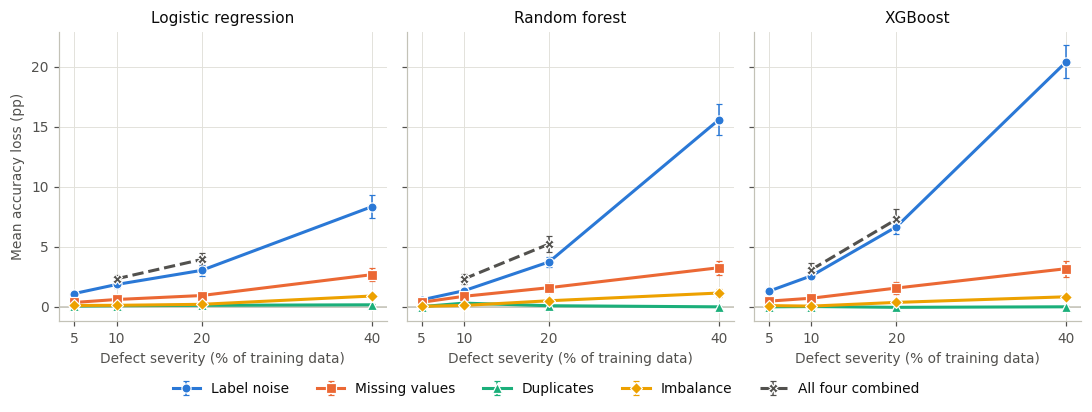

In [13]:
DEFECT_LABELS = {'label_noise': 'Label noise', 'missing': 'Missing values', 'duplicates': 'Duplicates',
                 'imbalance': 'Imbalance', 'combined': 'All four combined'}
DEFECT_STYLE = {
    'label_noise': dict(color=C_BLUE, marker='o', ls='-'),
    'missing': dict(color=C_ORANGE, marker='s', ls='-'),
    'duplicates': dict(color=C_AQUA, marker='^', ls='-'),
    'imbalance': dict(color=C_YELLOW, marker='D', ls='-'),
    'combined': dict(color=INK2, marker='X', ls='--'),
}

d2 = data.copy()
d2['level'] = [r['inj_' + r['defect_type']] if r['defect_type'] != 'combined' else r['inj_missing']
               for _, r in d2.iterrows()]
g = d2.groupby(['model', 'defect_type', 'level'])['degradation'].agg(['mean', 'sem']).reset_index()

fig, axes = plt.subplots(1, len(MODELS), figsize=(10, 3.5), sharey=True)
for ax, m in zip(np.atleast_1d(axes), MODELS):
    for dt, st in DEFECT_STYLE.items():
        s = g[(g['model'] == m) & (g['defect_type'] == dt)].sort_values('level')
        if s.empty:
            continue
        ax.errorbar(s['level'] * 100, s['mean'] * 100, yerr=s['sem'].fillna(0) * 100,
                    color=st['color'], marker=st['marker'], ls=st['ls'], lw=2, ms=6,
                    mec='white', mew=0.8, capsize=2, elinewidth=1, label=DEFECT_LABELS[dt])
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(MODEL_TITLES[m])
    ax.set_xlabel('Defect severity (% of training data)')
    ax.set_xticks([5, 10, 20, 40])
np.atleast_1d(axes)[0].set_ylabel('Mean accuracy loss (pp)')
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.07))
plt.tight_layout()
save_fig(fig, 'fig2_accuracy_loss_by_defect')
plt.show()

### Figure 3: predicted vs real accuracy loss

Each dot is one dataset with one problem setting, predicted by leave-one-dataset-out validation. Dots close to the dashed line are good predictions. Change `BEST_METHOD` to plot another method.

saved fig3_predicted_vs_real in /content/drive/MyDrive/data_quality_paper/figures


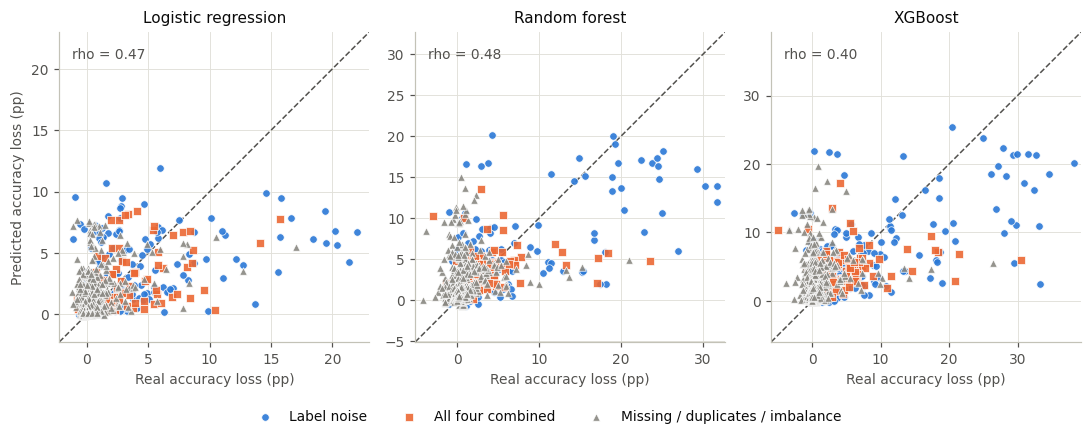

In [14]:
BEST_METHOD = 'forest (small set)'
GROUPS = [('label_noise', 'Label noise', C_BLUE, 'o'),
          ('combined', 'All four combined', C_ORANGE, 's'),
          (None, 'Missing / duplicates / imbalance', MUTED, '^')]

fig, axes = plt.subplots(1, len(MODELS), figsize=(10, 3.7))
for ax, m in zip(np.atleast_1d(axes), MODELS):
    d, preds = store[m]
    real = d['degradation'].to_numpy() * 100
    pred = preds[BEST_METHOD] * 100
    lo = min(real.min(), pred.min()) - 1
    hi = max(real.max(), pred.max()) + 1
    ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--', zorder=1)
    for key, label, color, marker in GROUPS:
        if key is None:
            mask = (~d['defect_type'].isin(['label_noise', 'combined'])).to_numpy()
        else:
            mask = (d['defect_type'] == key).to_numpy()
        ax.scatter(real[mask], pred[mask], s=24, color=color, marker=marker, edgecolor='white',
                   linewidth=0.5, alpha=0.9, label=label, zorder=2)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(MODEL_TITLES[m])
    ax.set_xlabel('Real accuracy loss (pp)')
    rho = spearmanr(real, pred)[0]
    ax.text(0.04, 0.95, 'rho = ' + format(rho, '.2f'), transform=ax.transAxes, va='top', color=INK2)
np.atleast_1d(axes)[0].set_ylabel('Predicted accuracy loss (pp)')
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
plt.tight_layout()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.0))
save_fig(fig, 'fig3_predicted_vs_real')
plt.show()

## The planned test: label noise on datasets the meta-model has never seen

**Hypothesis H1 (formulated after the first round, before any new dataset was run):** on label-noise cases of datasets that were *not* used to train the meta-model, `forest (small set)` has a lower average error than the `average drop` baseline.

**Procedure:** train on all problem types of the original 21 datasets. Test only on the label-noise cases of the new datasets.

**Decision rule:** H1 is supported for a model family if `p_vs_avg` is below **0.0167**. That is 0.05 divided by 3, because three model families are tested.

**Two baselines:**
- `average drop`: the average accuracy drop over all problem types seen in training.
- `type average (oracle)`: the average drop of label-noise cases in training. It is called an oracle because it cheats: it is told that the problem is label noise. In real life nobody knows this in advance.

**How to read it:**
- Beating `average drop` shows that the meta-features reveal that the labels are noisy.
- Beating the oracle as well shows that they also reveal **how bad** the noise is. That is the stronger claim.
- If the meta-model does not beat the oracle, report that honestly.

Columns: `better_than_avg` and `better_than_oracle` give on how many of the new datasets the meta-model has a smaller error. `p_vs_avg` and `p_vs_oracle` come from a one-sided paired Wilcoxon test. `rank_corr` is the Spearman correlation between predicted and real drops over all label-noise cases.

In [15]:
ALPHA = 0.05 / 3        # three model families, Bonferroni correction
TYPE = 'label_noise'

orig_data = data[data['dataset_id'].isin(ORIGINAL_IDS)]
new_data = data[~data['dataset_id'].isin(ORIGINAL_IDS)]
n_new = new_data['dataset_id'].nunique()
print('Original datasets used for training:', orig_data['dataset_id'].nunique())
print('New datasets finished:', n_new, 'of', len(NEW_IDS))
if n_new < len(NEW_IDS):
    print('Note: not all new datasets finished. The planned test is complete only when all of them are done.')

conf_rows = []
conf_err = {}
if n_new > 0:
    for m in MODELS:
        tr = orig_data[orig_data['model'] == m]
        te = new_data[(new_data['model'] == m) & (new_data['defect_type'] == TYPE)].reset_index(drop=True)
        y_tr = tr['degradation'].to_numpy()
        y_te = te['degradation'].to_numpy()
        cols = FEATURE_SETS['small']

        forest = make_meta('forest_small').fit(tr[cols], y_tr)
        preds = {
            'average drop': np.full(len(te), y_tr.mean()),
            'type average (oracle)': np.full(len(te), tr.loc[tr['defect_type'] == TYPE, 'degradation'].mean()),
            'forest (small set)': forest.predict(te[cols]),
        }
        err = {k: pd.Series(np.abs(y_te - p)).groupby(te['dataset_id']).mean() for k, p in preds.items()}
        conf_err[m] = err

        for name, p in preds.items():
            row = {'model': m, 'method': name, 'MAE': np.abs(y_te - p).mean()}
            if name == 'forest (small set)':
                row['rank_corr'] = spearmanr(y_te, p)[0]
                for ref, tag in [('average drop', 'avg'), ('type average (oracle)', 'oracle')]:
                    diff = err[name] - err[ref]
                    row['better_than_' + tag] = str(int((diff < 0).sum())) + '/' + str(len(diff))
                    try:
                        row['p_vs_' + tag] = wilcoxon(err[name], err[ref], alternative='less').pvalue
                    except Exception:
                        row['p_vs_' + tag] = np.nan
            conf_rows.append(row)

conf_df = pd.DataFrame(conf_rows).round(4)
if len(conf_df):
    conf_df['supports_H1'] = np.where(
        (conf_df['method'] == 'forest (small set)') & (conf_df['p_vs_avg'] < ALPHA), 'yes', '')
conf_df

Original datasets used for training: 21
New datasets finished: 27 of 27


,model,method,MAE,rank_corr,better_than_avg,p_vs_avg,better_than_oracle,p_vs_oracle,supports_H1
0,logreg,average drop,0.0285,NaN,NaN,NaN,NaN,NaN,
1,logreg,type average (oracle),0.0368,NaN,NaN,NaN,NaN,NaN,
2,logreg,forest (small set),0.0307,0.3571,15/27,0.4764,19/27,0.0276,
3,rf,average drop,0.0464,NaN,NaN,NaN,NaN,NaN,
4,rf,type average (oracle),0.0563,NaN,NaN,NaN,NaN,NaN,
5,rf,forest (small set),0.0345,0.6849,23/27,0.0004,24/27,0.0000,yes
6,xgb,average drop,0.0616,NaN,NaN,NaN,NaN,NaN,
7,xgb,type average (oracle),0.0714,NaN,NaN,NaN,NaN,NaN,
8,xgb,forest (small set),0.0479,0.5374,23/27,0.0004,23/27,0.0000,yes


### Figure 4: the planned test, dataset by dataset

Each dot is one **new** dataset (label-noise cases only). The horizontal axis is the error of the `average drop` baseline, the vertical axis is the error of the meta-model. A dot **below the dashed line** means the meta-model was better on that dataset. This is the figure that shows the planned test at a glance.

saved fig4_planned_test_per_dataset in /content/drive/MyDrive/data_quality_paper/figures


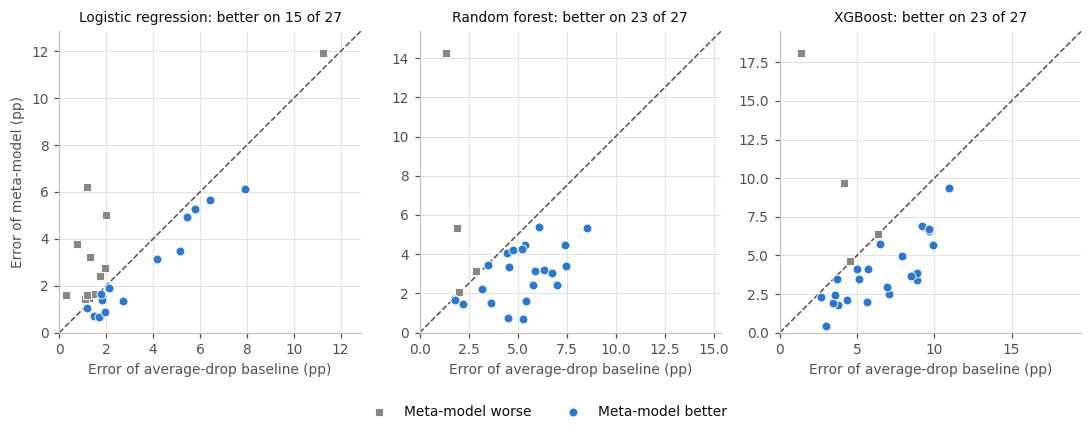

In [16]:
if len(conf_err) > 0:
    fig, axes = plt.subplots(1, len(MODELS), figsize=(10, 3.7))
    for ax, m in zip(np.atleast_1d(axes), MODELS):
        e = conf_err[m]
        x = e['average drop'].to_numpy() * 100
        y = e['forest (small set)'].to_numpy() * 100
        better = y < x
        hi = max(x.max(), y.max()) * 1.08
        ax.plot([0, hi], [0, hi], color=INK2, lw=1, ls='--', zorder=1)
        ax.scatter(x[~better], y[~better], s=34, color=MUTED, marker='s', edgecolor='white',
                   linewidth=0.6, label='Meta-model worse', zorder=2)
        ax.scatter(x[better], y[better], s=34, color=C_BLUE, marker='o', edgecolor='white',
                   linewidth=0.6, label='Meta-model better', zorder=2)
        ax.set_xlim(0, hi)
        ax.set_ylim(0, hi)
        ax.set_aspect('equal', adjustable='box')
        ax.set_title(MODEL_TITLES[m] + ': better on ' + str(int(better.sum())) + ' of ' + str(len(better)), fontsize=9)
        ax.set_xlabel('Error of average-drop baseline (pp)')
    np.atleast_1d(axes)[0].set_ylabel('Error of meta-model (pp)')
    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    plt.tight_layout()
    fig.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.0))
    save_fig(fig, 'fig4_planned_test_per_dataset')
    plt.show()
else:
    print('Figure 4 needs the new datasets to be finished. Run the planned-test cell first.')

### Figure 5: which meta-features matter most?

Importance of each meta-feature in the random forest that uses all 16 features, averaged over the three target models. Colours show the feature group.

saved fig5_feature_importance in /content/drive/MyDrive/data_quality_paper/figures


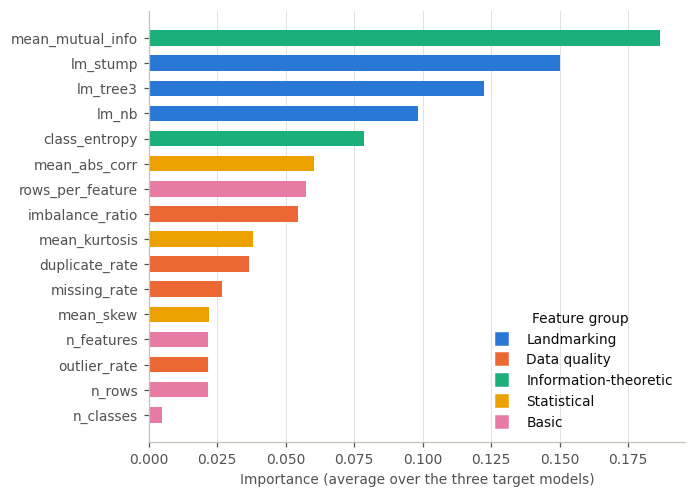

In [17]:
imp = pd.DataFrame(index=META_COLS)
for m in MODELS:
    d = data[data['model'] == m]
    pipe = make_meta('forest').fit(d[META_COLS], d['degradation'])
    imp[m] = pipe[-1].feature_importances_
imp['average'] = imp.mean(axis=1)

GROUP_OF = {'n_rows': 'Basic', 'n_features': 'Basic', 'n_classes': 'Basic', 'rows_per_feature': 'Basic',
            'missing_rate': 'Data quality', 'duplicate_rate': 'Data quality',
            'imbalance_ratio': 'Data quality', 'outlier_rate': 'Data quality',
            'mean_skew': 'Statistical', 'mean_kurtosis': 'Statistical', 'mean_abs_corr': 'Statistical',
            'class_entropy': 'Information-theoretic', 'mean_mutual_info': 'Information-theoretic',
            'lm_stump': 'Landmarking', 'lm_tree3': 'Landmarking', 'lm_nb': 'Landmarking'}
GROUP_COLOR = {'Landmarking': C_BLUE, 'Data quality': C_ORANGE, 'Information-theoretic': C_AQUA,
               'Statistical': C_YELLOW, 'Basic': C_MAGENTA}

s = imp['average'].sort_values()
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.barh(list(s.index), s.values, color=[GROUP_COLOR[GROUP_OF[f]] for f in s.index], height=0.62)
ax.set_xlabel('Importance (average over the three target models)')
ax.grid(axis='y', visible=False)
handles = [Line2D([0], [0], marker='s', ls='', color=c, ms=8, label=gname) for gname, c in GROUP_COLOR.items()]
ax.legend(handles=handles, loc='lower right', title='Feature group')
plt.tight_layout()
save_fig(fig, 'fig5_feature_importance')
plt.show()

In [18]:
data.to_csv(os.path.join(OUTPUT_DIR, 'final_data_averaged.csv'), index=False)
summary_df.to_csv(os.path.join(OUTPUT_DIR, 'final_summary.csv'), index=False)
breakdown.to_csv(os.path.join(OUTPUT_DIR, 'final_breakdown.csv'), index=False)
imp.to_csv(os.path.join(OUTPUT_DIR, 'final_feature_importance.csv'))
conf_df.to_csv(os.path.join(OUTPUT_DIR, 'final_planned_test_label_noise.csv'), index=False)
print('Saved final_*.csv files in', OUTPUT_DIR)
print('Figures are in', FIG_DIR)

Saved final_*.csv files in /content/drive/MyDrive/data_quality_paper
Figures are in /content/drive/MyDrive/data_quality_paper/figures


## What to send back

1. The three tables: the planned-test table (the one with `supports_H1`), the summary table of the five methods, and the breakdown table.
2. The four figure files from the `figures` folder in your Drive (the `.png` files). Or screenshots of the four charts.

Then I'll put the results and the figures into the paper draft.

## Extra checks (ablation and noise-level baseline)
Run this after the planned-test cell. It adds the two checks the paper still needs.

In [ ]:
# ============================================================
# EXTRA CHECKS (run this as ONE new cell at the very end of the notebook,
# after the planned-test cell has been run)
#
# Check 1 (ablation): does the meta-model still work without the
#          landmarking and mutual-information features?
# Check 2 (noise-level baseline): how does the meta-model compare with a
#          baseline that is TOLD the true label-noise level?
# ============================================================
from scipy.stats import spearmanr, wilcoxon
from sklearn.linear_model import LinearRegression

TYPE = 'label_noise'
LM_COLS = ['lm_stump', 'lm_tree3', 'lm_nb']
MI_COLS = ['mean_mutual_info']

ABLATION_SETS = {
    'small set (the one used in the paper)': FEATURE_SETS['small'],
    'small set WITHOUT landmarking':          [c for c in FEATURE_SETS['small'] if c not in LM_COLS],
    'landmarking ONLY':                       LM_COLS,
    'all 16 WITHOUT landmarking and MI':      [c for c in META_COLS if c not in LM_COLS + MI_COLS],
}

orig_data = data[data['dataset_id'].isin(ORIGINAL_IDS)]
new_data = data[~data['dataset_id'].isin(ORIGINAL_IDS)]


def per_dataset_mae(y_true, y_pred, ds_ids):
    return pd.Series(np.abs(y_true - y_pred)).groupby(np.asarray(ds_ids)).mean()


def one_sided_p(a, b):
    """p-value that errors in a are lower than errors in b (Wilcoxon, one-sided)."""
    try:
        return wilcoxon(a, b, alternative='less').pvalue
    except Exception:
        return np.nan


rows1, rows2 = [], []
for m in MODELS:
    tr = orig_data[orig_data['model'] == m]
    te = new_data[(new_data['model'] == m) & (new_data['defect_type'] == TYPE)].reset_index(drop=True)
    y_tr, y_te = tr['degradation'].to_numpy(), te['degradation'].to_numpy()
    ds = te['dataset_id'].to_numpy()
    level = te['inj_label_noise'].to_numpy()

    base_err = per_dataset_mae(y_te, np.full(len(te), y_tr.mean()), ds)      # average drop

    # ---------------- Check 1: ablation ----------------
    for name, cols in ABLATION_SETS.items():
        pred = make_meta('forest_small').fit(tr[cols], y_tr).predict(te[cols])
        err = per_dataset_mae(y_te, pred, ds)
        rows1.append({'model': m, 'features': name, 'n_feat': len(cols),
                      'MAE': np.abs(y_te - pred).mean(),
                      'MAE_avg_drop': np.abs(y_te - y_tr.mean()).mean(),
                      'better_on': str(int((err < base_err).sum())) + '/' + str(len(err)),
                      'p_vs_avg': one_sided_p(err, base_err),
                      'rank_corr_vs_real': spearmanr(y_te, pred)[0],
                      'rank_corr_vs_noise_level': spearmanr(level, pred)[0]})

    # ---------------- Check 2: baselines told the true noise level ----------------
    tr_ln = tr[tr['defect_type'] == TYPE]
    cols_small = FEATURE_SETS['small']
    meta_pred = make_meta('forest_small').fit(tr[cols_small], y_tr).predict(te[cols_small])

    # (a) average loss seen in training at exactly this noise level
    table = tr_ln.groupby('inj_label_noise')['degradation'].mean()
    pred_level_table = np.array([table.get(l, table.iloc[(table.index - l).to_numpy().__abs__().argmin()]) for l in level])
    # (b) straight-line fit of loss against noise level
    lin = LinearRegression().fit(tr_ln[['inj_label_noise']], tr_ln['degradation'])
    pred_level_lin = lin.predict(te[['inj_label_noise']])
    # (c) noise level + dataset features together (trained on label-noise rows only)
    cols_c = ['inj_label_noise'] + cols_small
    pred_both = make_meta('forest_small').fit(tr_ln[cols_c], tr_ln['degradation']).predict(te[cols_c])

    candidates = {
        'average drop (knows nothing)': np.full(len(te), y_tr.mean()),
        'meta-model (paper, NOT told the noise level)': meta_pred,
        'told the noise level: average loss at that level': pred_level_table,
        'told the noise level: straight-line fit': pred_level_lin,
        'told the noise level + dataset features': pred_both,
    }
    errs = {k: per_dataset_mae(y_te, p, ds) for k, p in candidates.items()}
    meta_err = errs['meta-model (paper, NOT told the noise level)']
    for k, p in candidates.items():
        e = errs[k]
        rows2.append({'model': m, 'method': k, 'MAE': np.abs(y_te - p).mean(),
                      'rank_corr_vs_real': np.nan if k.startswith('average') else spearmanr(y_te, p)[0],
                      'meta_better_on': '' if k.startswith('meta') else
                          str(int((meta_err < e).sum())) + '/' + str(len(e)),
                      'p_meta_lower': np.nan if k.startswith('meta') else one_sided_p(meta_err, e)})

check1 = pd.DataFrame(rows1).round(4)
check2 = pd.DataFrame(rows2).round(4)

pd.set_option('display.width', 250, 'display.max_columns', 30, 'display.max_colwidth', 60)
print('CHECK 1: ablation on the unseen datasets (label-noise cases)')
print(check1.to_string(index=False))
print()
print('CHECK 2: meta-model versus baselines that are told the true noise level')
print(check2.to_string(index=False))

check1.to_csv(os.path.join(OUTPUT_DIR, 'check1_ablation.csv'), index=False)
check2.to_csv(os.path.join(OUTPUT_DIR, 'check2_noise_level_baseline.csv'), index=False)
print('\nSaved check1_ablation.csv and check2_noise_level_baseline.csv in', OUTPUT_DIR)
